# Customer Churn — отток клиентов

Директор по продуктам: «Мы теряем клиентов. Нужна модель, которая покажет, кто уйдёт следующим».

Готового события «ушёл» нет: клиент не расторгает договор, карта остаётся в кармане. Таргет задаём сами.

Графики ниже — разбор таргета. Тот же вывод сохраняется в `presentation/assets/` для слайдов.

Окружение проекта: `uv sync` в `projects/customer_churn`, ядро **customer_churn**.


In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

%matplotlib inline

HERE = Path.cwd()
if (HERE / "data" / "targets").exists():
    PROJECT = HERE
elif (HERE.parent / "data" / "targets").exists():
    PROJECT = HERE.parent
else:
    PROJECT = Path("..").resolve()

TARGETS = PROJECT / "data" / "targets"
ASSETS = PROJECT / "presentation" / "assets"
ASSETS.mkdir(parents=True, exist_ok=True)

SLIDE = "#e6e2da"
INK = "#2d3038"
MUTED = "#5c616b"
DIM = "#7a7f88"
ACCENT = "#355f8c"
WARN = "#9a3b36"
OK = "#2f6b64"
LINE = "#cfcbc4"
BAR = "#b7b3ab"
SOFT = "#4d739c"

plt.rcParams.update({
    "font.size": 12,
    "text.color": INK,
    "axes.labelcolor": MUTED,
    "axes.edgecolor": LINE,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.facecolor": SLIDE,
    "figure.facecolor": SLIDE,
    "axes.linewidth": 0.9,
    "axes.titlesize": 14,
    "axes.titlelocation": "left",
    "axes.titlecolor": INK,
    "axes.titlepad": 10,
    "figure.dpi": 120,
})


def save(fig, name: str) -> Path:
    path = ASSETS / name
    fig.savefig(path, facecolor=SLIDE, bbox_inches="tight", pad_inches=0.22, dpi=180)
    print("→", path.relative_to(PROJECT))
    return path


usage = pd.read_csv(TARGETS / "target_60d_usage.csv", parse_dates=["snapshot_date"])
july = usage.loc[usage["snapshot_date"] == "2025-07-31"].copy()
n = july["horizon_n_txn"].astype(int)
amt = july["horizon_amount_uzs"]
print("проект:", PROJECT)
print("когорта июля:", len(july), "  отток:", f"{july['target'].mean():.1%}")


проект: /Users/user/Projects/Learning/Uzcard Academy/projects/customer_churn
когорта июля: 12021   отток: 17.3%


## 1. Кого считаем ушедшим

В когорте на t0: стаж пользования ≥ 60 дней (от первой approved), последняя операция не старше 60 дней.

**Жив**, если за следующие 60 дней есть ≥ 3 approved **и** сумма ≥ 800 тыс. (p5 среди тех, у кого уже ≥ 3). Иначе `target = 1`.

Одна зарплата или два перевода — ещё не «наш клиент». Три платежа по тысяче — тоже нет.


### Касания: почему пол = 3, а не 4 или 5

Смотрим июльскую когорту. Слева — из скольких операций она состоит. Справа — что будет с долей оттока, если поднять минимум операций, оставив порог суммы.


  корзина  человек
0       0      905
1       1      240
2       2      404
3       3      530
4     4–5     1272
5    6–10     3495
6     11+     5175


→ presentation/assets/why_three_dist.png


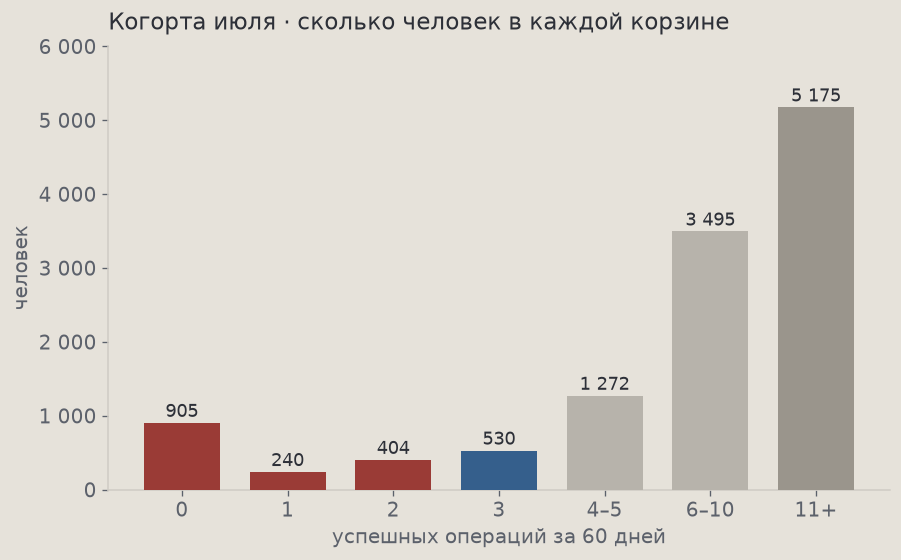

In [2]:
def usage_churn(floor: int) -> pd.Series:
    few = n < floor
    poor = (n >= floor) & (amt < 800_000)
    return (few | poor) & (n < 20)


buckets = [
    ("0", int((n == 0).sum()), WARN),
    ("1", int((n == 1).sum()), WARN),
    ("2", int((n == 2).sum()), WARN),
    ("3", int((n == 3).sum()), ACCENT),
    ("4–5", int(((n >= 4) & (n <= 5)).sum()), BAR),
    ("6–10", int(((n >= 6) & (n <= 10)).sum()), BAR),
    ("11+", int((n >= 11).sum()), "#9a958c"),
]
print(pd.DataFrame(buckets, columns=["корзина", "человек", "_"]).drop(columns="_"))

fig, ax = plt.subplots(figsize=(8.4, 4.8))
xs = np.arange(len(buckets))
ax.bar(xs, [b[1] for b in buckets], color=[b[2] for b in buckets], width=0.72, zorder=3)
for i, (_, cnt, _) in enumerate(buckets):
    ax.text(i, cnt + 80, f"{cnt:,}".replace(",", " "), ha="center", fontsize=11, color=INK)
ax.set_xticks(xs)
ax.set_xticklabels([b[0] for b in buckets])
ax.set_xlabel("успешных операций за 60 дней")
ax.set_ylabel("человек")
ax.set_ylim(0, max(b[1] for b in buckets) * 1.16)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}".replace(",", " ")))
ax.set_title("Когорта июля · сколько человек в каждой корзине")
save(fig, "why_three_dist.png");


пол 3: 17.3%
пол 4: 20.1%  +340 живых
пол 5: 24.0%  +807
при ровно 3 операциях живых 340, медиана суммы 1.9 млн
→ presentation/assets/why_three_cost.png


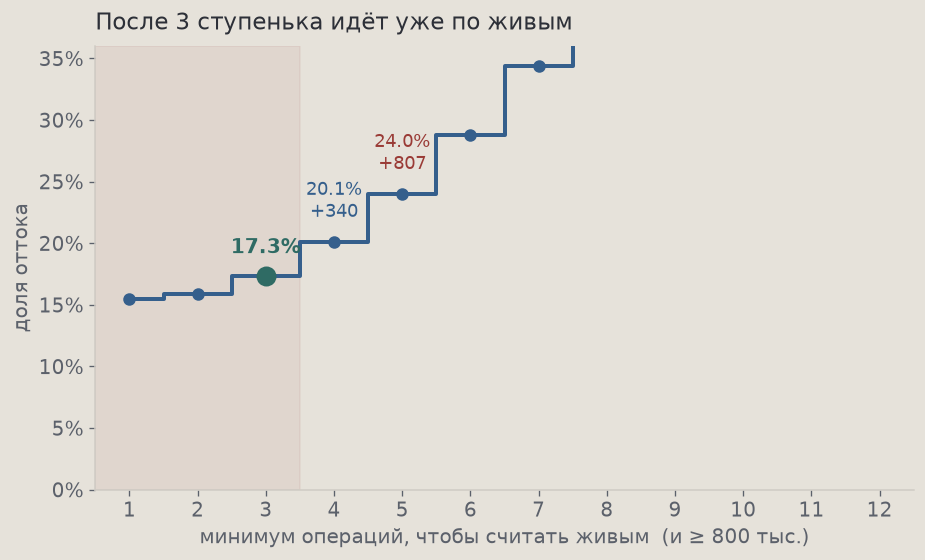

In [3]:
floors = np.arange(1, 13)
rates = np.array([usage_churn(int(k)).mean() * 100 for k in floors])
heads = np.array([int(usage_churn(int(k)).sum()) for k in floors])
i3 = int(np.where(floors == 3)[0][0])
extra = heads - heads[i3]
n3_alive = int(((n == 3) & (amt >= 800_000)).sum())
n3_med = float(july.loc[(n == 3) & (amt >= 800_000), "horizon_amount_uzs"].median())

print("пол 3:", f"{rates[i3]:.1f}%")
print("пол 4:", f"{rates[i3+1]:.1f}%  +{extra[i3+1]} живых")
print("пол 5:", f"{rates[i3+2]:.1f}%  +{extra[i3+2]}")
print(f"при ровно 3 операциях живых {n3_alive}, медиана суммы {n3_med/1e6:.1f} млн")

fig, ax = plt.subplots(figsize=(8.8, 4.8))
ax.axvspan(0.5, 3.5, color=WARN, alpha=0.07, zorder=0)
ax.step(floors, rates, where="mid", color=ACCENT, lw=2.4, zorder=3)
ax.plot(floors, rates, "o", color=ACCENT, ms=6.5, zorder=4)
ax.plot(3, rates[i3], "o", color=OK, ms=11, zorder=5)
ax.text(3, rates[i3] + 1.5, f"{rates[i3]:.1f}%", ha="center", va="bottom", fontsize=12, color=OK, fontweight="bold")
ax.text(4, rates[i3 + 1] + 1.5, f"{rates[i3 + 1]:.1f}%\n+{extra[i3 + 1]}", ha="center", va="bottom", fontsize=11, color=ACCENT)
ax.text(5, rates[i3 + 2] + 1.5, f"{rates[i3 + 2]:.1f}%\n+{extra[i3 + 2]}", ha="center", va="bottom", fontsize=11, color=WARN)
ax.set_xlim(0.5, 12.5)
ax.set_ylim(0, 36)
ax.set_xticks(floors)
ax.set_xlabel("минимум операций, чтобы считать живым  (и ≥ 800 тыс.)")
ax.set_ylabel("доля оттока")
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.0f%%"))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_title("После 3 ступенька идёт уже по живым")
save(fig, "why_three_cost.png");


### Сумма: p5 только среди тех, кто уже ходит ≥ 3 раз

Если ранжировать всех, нули и одна зарплата стянут порог вниз. Сначала отсекаем разовых, потом берём хвост по сумме.


когорта 12 021  →  ≥3 ops 10 472 (−1 549)  →  p5 794 067  →  крошки −532  →  живых 9 940


→ presentation/assets/percentile_steps.png


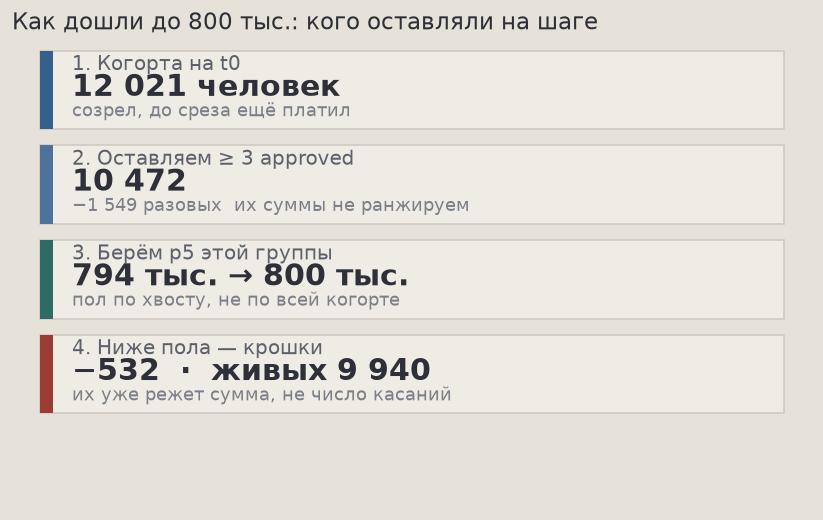

In [4]:
cohort = len(july)
ge3 = int((n >= 3).sum())
few = cohort - ge3
p5 = float(july.loc[n >= 3, "horizon_amount_uzs"].quantile(0.05))
poor = int(((n >= 3) & (amt < 800_000)).sum())
keep = ge3 - poor

print(f"когорта {cohort:,}  →  ≥3 ops {ge3:,} (−{few:,})  →  p5 {p5:,.0f}  →  крошки −{poor}  →  живых {keep:,}".replace(",", " "))

fig, ax = plt.subplots(figsize=(8.6, 5.0))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")
steps = [
    (8.2, ACCENT, "1. Когорта на t0", f"{cohort:,} человек".replace(",", " "), "созрел, до среза ещё платил"),
    (6.15, SOFT, "2. Оставляем ≥ 3 approved", f"{ge3:,}".replace(",", " "), f"−{few:,} разовых, их суммы не ранжируем".replace(",", " ")),
    (4.1, OK, "3. Берём p5 этой группы", f"{p5/1000:,.0f} тыс. → 800 тыс.".replace(",", " "), "пол по хвосту, не по всей когорте"),
    (2.05, WARN, "4. Ниже пола — крошки", f"−{poor}  ·  живых {keep:,}".replace(",", " "), "их уже режет сумма, не число касаний"),
]
for y, color, title, big, sub in steps:
    ax.add_patch(plt.Rectangle((0.35, y), 9.3, 1.7, facecolor="#efece6", edgecolor=LINE, linewidth=1))
    ax.add_patch(plt.Rectangle((0.35, y), 0.16, 1.7, facecolor=color, edgecolor="none"))
    ax.text(0.75, y + 1.28, title, fontsize=12, color=MUTED)
    ax.text(0.75, y + 0.72, big, fontsize=18, color=INK, fontweight="bold")
    ax.text(0.75, y + 0.28, sub, fontsize=11, color=DIM)
ax.set_title("Как дошли до 800 тыс.: кого оставляли на шаге")
save(fig, "percentile_steps.png");


p5: 794 тыс. за 60 дней  →  отток 17.2%
p10: 1 195 тыс. за 60 дней  →  отток 21.6%
p15: 1 567 тыс. за 60 дней  →  отток 26.0%


→ presentation/assets/percentiles.png


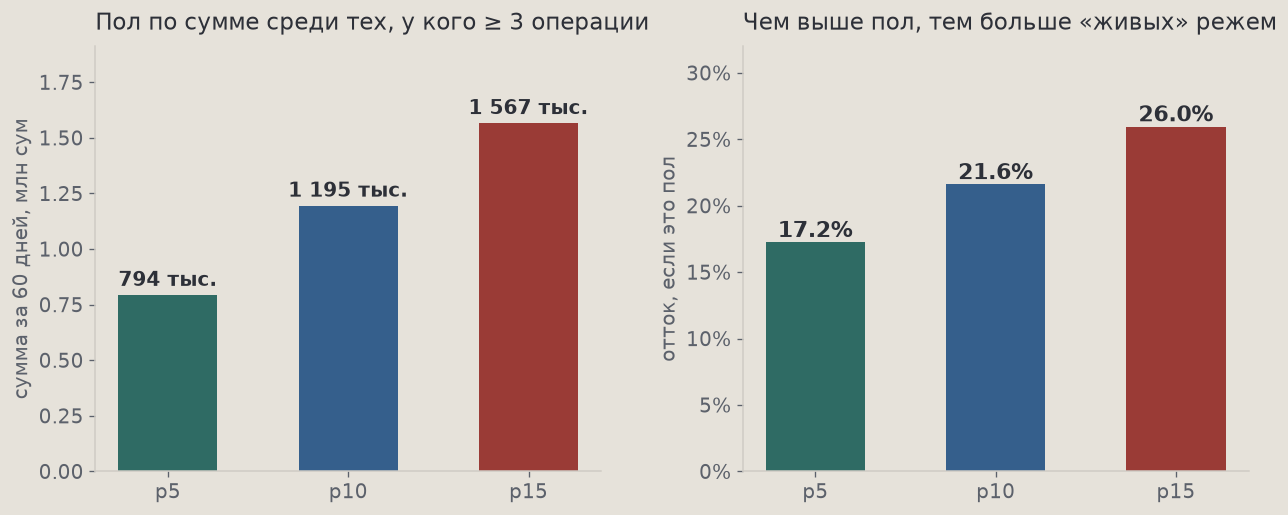

In [5]:
g = july.loc[n >= 3, "horizon_amount_uzs"]
specs = [
    (5, "794 → 800 тыс.", "хвост крошек", OK),
    (10, "1,2 млн", "уже скромные живые", ACCENT),
    (15, "1,6 млн", "ещё больше живых", WARN),
]
rows = []
for p, amt_s, meaning, col in specs:
    v = float(g.quantile(p / 100))
    flag = (n < 3) | ((n >= 3) & (amt < v))
    rows.append(dict(p=p, v=v, rate=flag.mean() * 100, cnt=int(flag.sum()), amt_s=amt_s, meaning=meaning, col=col))
    print(f"p{p}: {v/1000:,.0f} тыс.  →  отток {rows[-1]['rate']:.1f}%".replace(",", " "))

shown = [round(r["rate"], 1) for r in rows]
base_n = rows[0]["cnt"]

fig, ax = plt.subplots(figsize=(12.8, 5.2))
xs = np.arange(3)
ax.bar(xs, [r["rate"] for r in rows], width=0.55, color=[r["col"] for r in rows], zorder=3)
for i, r in enumerate(rows):
    ax.text(i, r["rate"] + 0.7, f"{shown[i]:.1f}%", ha="center", va="bottom",
            fontsize=18, fontweight="bold", color=r["col"])
    if i == 0:
        ax.text(i, r["rate"] * 0.52, "берём", ha="center", va="center",
                fontsize=13, color="white", fontweight="bold")
    else:
        ax.text(i, r["rate"] * 0.48,
                f"ещё {r['cnt'] - base_n} живых",
                ha="center", va="center", fontsize=13, color="white", fontweight="bold")
ax.set_xticks(xs)
ax.set_xticklabels([f"p{r['p']}\n{r['amt_s']}\n{r['meaning']}" for r in rows], fontsize=12, color=INK)
ax.set_ylabel("доля оттока, если взять этот пол")
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.0f%%"))
ax.set_ylim(0, 32)
ax.set_xlim(-0.55, 2.55)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", length=0, pad=8)
ax.set_title("p5 режет хвост. p10 и p15 уже забирают живых")
save(fig, "percentiles.png");


p10 — уже скромный, но живой. Между p5 и p10 сотни человек с ≥ 3 операциями: назвать их ушедшими — путать «мало тратит» с «ушёл».


между p5 и p10: 524 человек


→ presentation/assets/why_p5.png


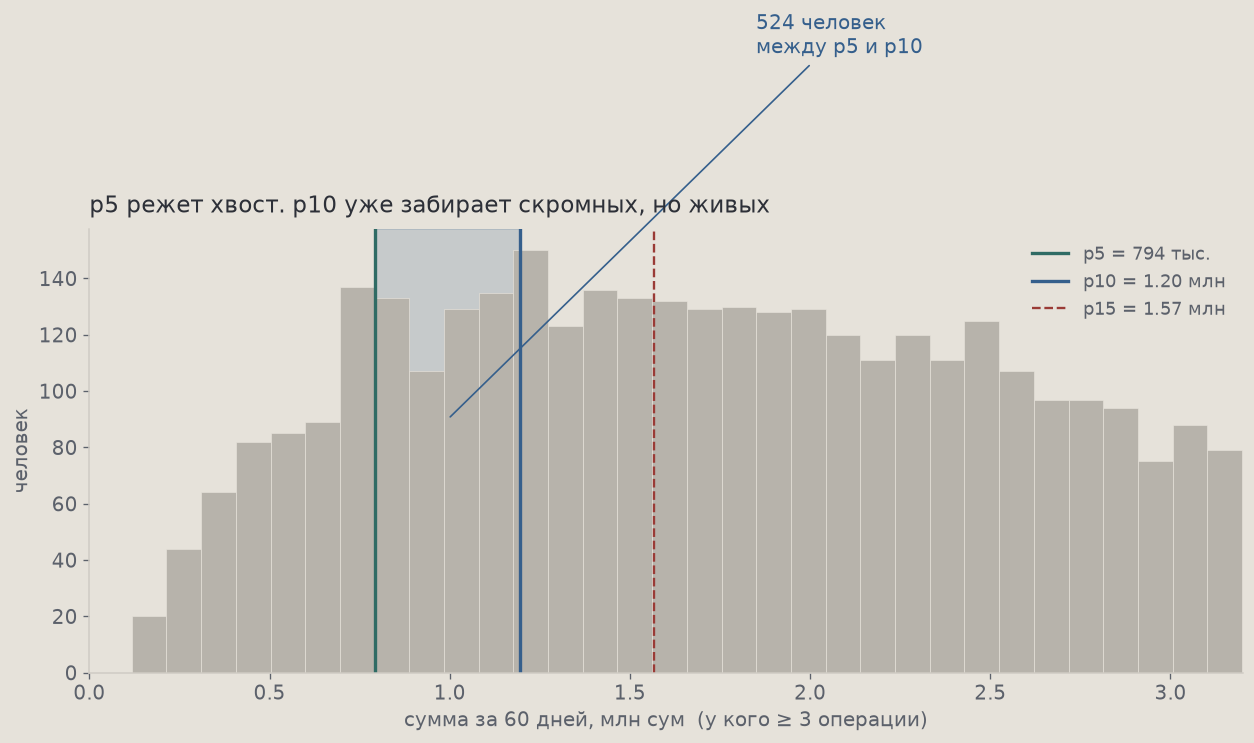

In [6]:
g_mln = g / 1e6
p5v, p10v, p15v = (g_mln.quantile(p) for p in (0.05, 0.10, 0.15))
mid = int(((n >= 3) & (amt >= p5v * 1e6) & (amt < p10v * 1e6)).sum())
print(f"между p5 и p10: {mid} человек")

fig, ax = plt.subplots(figsize=(12.4, 4.8))
shown = g_mln[g_mln <= 3.2]
ax.hist(shown, bins=32, color=BAR, edgecolor=SLIDE, linewidth=0.4, zorder=2)
ax.axvspan(p5v, p10v, color=ACCENT, alpha=0.18, zorder=1)
ax.axvline(p5v, color=OK, lw=2, label=f"p5 = {p5v*1000:.0f} тыс.")
ax.axvline(p10v, color=ACCENT, lw=2, label=f"p10 = {p10v:.2f} млн")
ax.axvline(p15v, color=WARN, lw=1.4, ls="--", label=f"p15 = {p15v:.2f} млн")
ax.annotate(f"{mid} человек\nмежду p5 и p10", xy=((p5v + p10v) / 2, 90), xytext=(1.85, 220),
            fontsize=12, color=ACCENT, arrowprops=dict(arrowstyle="-", color=ACCENT, lw=1))
ax.set_xlim(0, 3.2)
ax.set_xlabel("сумма за 60 дней, млн сум  (у кого ≥ 3 операции)")
ax.set_ylabel("человек")
ax.set_title("p5 режет хвост. p10 уже забирает скромных, но живых")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="upper right", fontsize=11, labelcolor=MUTED)
save(fig, "why_p5.png");


## 2. База на срезе 31 июля

Сначала когорта (ещё пользовался до t0), потом фильтр касаний, потом сумма. Отказы в ярлык не входят.


→ presentation/assets/funnel.png


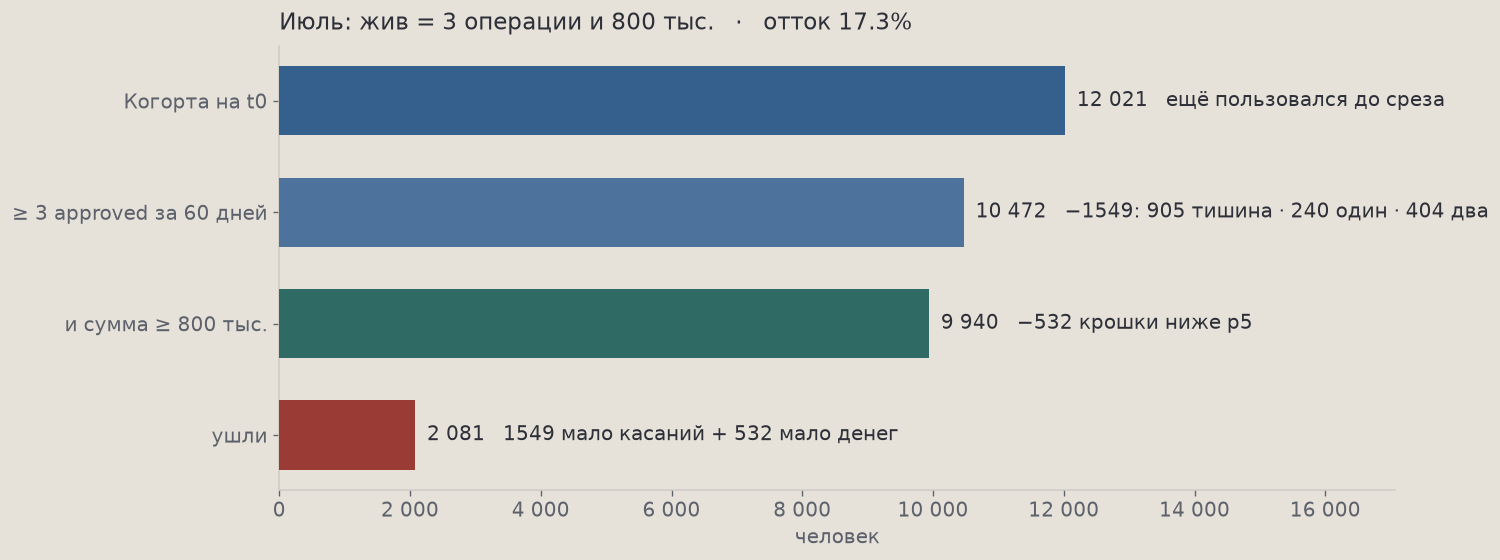

In [7]:
alive = int(((n >= 3) & (amt >= 800_000)).sum())
n0, n1, n2 = int((n == 0).sum()), int((n == 1).sum()), int((n == 2).sum())
few_n = int((n < 3).sum())
poor_n = int(((n >= 3) & (amt < 800_000)).sum())
churn_n = int(july["target"].sum())
rate = july["target"].mean() * 100

fig, ax = plt.subplots(figsize=(12.0, 4.8))
labels = ["Когорта на t0", "≥ 3 approved за 60 дней", "и сумма ≥ 800 тыс.", "ушли"]
values = [cohort, ge3, alive, churn_n]
colors = [ACCENT, SOFT, OK, WARN]
notes = [
    "ещё пользовался до среза",
    f"−{few_n}: {n0} тишина · {n1} один · {n2} два",
    f"−{poor_n} крошки ниже p5",
    f"{few_n} мало касаний + {poor_n} мало денег",
]
y = np.arange(len(labels))[::-1]
ax.barh(y, values, color=colors, height=0.62, zorder=3)
for yi, v, note in zip(y, values, notes):
    ax.text(v + 180, yi, f"{v:,}   {note}".replace(",", " "), va="center", fontsize=12, color=INK)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlim(0, cohort * 1.42)
ax.set_xlabel("человек")
ax.set_title(f"Июль: жив = 3 операции и 800 тыс.   ·   отток {rate:.1f}%")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}".replace(",", " ")))
save(fig, "funnel.png");


## 3. Динамика: 1 июля комиссия выросла втрое

Рост оттока в июне–июле виден и на нашем ярлыке, и на простой тишине 60 дней. Значит это не артефакт порога «3 операции + p5». Горизонт июня уже захватывает 1 июля.


→ presentation/assets/tariff.png


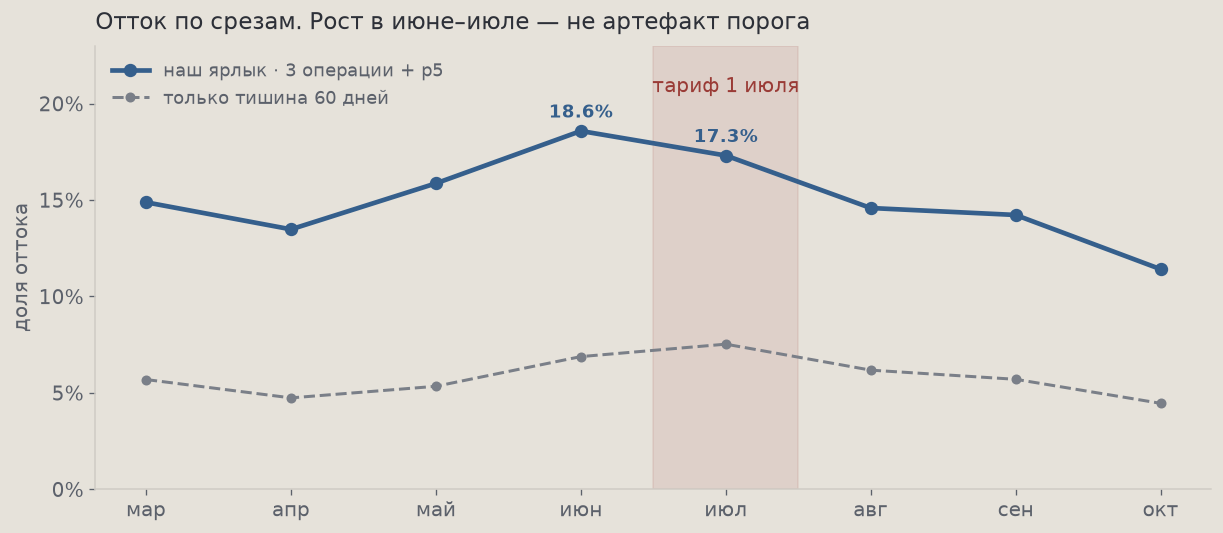

In [8]:
funnel = pd.read_csv(TARGETS / "funnel_60d_usage.csv", parse_dates=["snapshot_date"])
funnel = funnel.loc[funnel["horizon_closed"]].copy()
months = ["мар", "апр", "май", "июнь", "июль", "авг", "сен", "окт"]
x = np.arange(len(funnel))
usage_r = funnel["usage_churn_rate"] * 100
silence_r = funnel["silence_churn_rate"] * 100

fig, ax = plt.subplots(figsize=(12.8, 5.0))
ax.axvspan(2.55, 3.45, color=WARN, alpha=0.12, zorder=0)
ax.plot(x, usage_r, color=ACCENT, lw=2.8, marker="o", ms=7, label="наш отток", zorder=3)
ax.plot(x, silence_r, color=DIM, lw=1.6, ls="--", marker="o", ms=4.5, label="просто 60 дней без операций", zorder=2)
ax.annotate(
    f"{usage_r.iloc[3]:.1f}%\nв эти 60 дней уже был новый тариф".replace(".", ","),
    xy=(3, usage_r.iloc[3]),
    xytext=(0.35, 20.2),
    fontsize=12,
    color=ACCENT,
    fontweight="bold",
    arrowprops=dict(arrowstyle="-", color=ACCENT, lw=1),
)
ax.set_xticks(x)
ax.set_xticklabels(months)
for tick, lab in zip(ax.get_xticklabels(), months):
    if lab == "июнь":
        tick.set_color(WARN)
        tick.set_fontweight("bold")
ax.set_ylabel("доля оттока")
ax.set_ylim(0, 24)
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.0f%%"))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="upper left", fontsize=11, labelcolor=MUTED)
ax.set_title("Пик в июне: срез 30 июня смотрит вперёд — и уже видит тариф 1 июля")
save(fig, "tariff.png");


## 4–6. Фичи, модель, бизнес

Сборка фичей и обучение — `scripts/build_features.py`, `scripts/train_first_model.py`. Out-of-time: июль → сентябрь.


In [9]:
metrics = PROJECT / "data" / "model" / "metrics.json"
imp = PROJECT / "data" / "model" / "importance_gain.csv"
if metrics.exists():
    import json
    print(json.loads(metrics.read_text()))
else:
    print("модели ещё нет — сначала scripts/train_first_model.py")
if imp.exists():
    print(pd.read_csv(imp).head(10).to_string(index=False))


{'july_n': 12092, 'july_churn_rate': 0.07566986437313926, 'sep_n': 12203, 'sep_churn_rate': 0.05769073178726543, 'july_insample_auc': 0.9863529271420476, 'july_insample_ap': 0.8201662389428005, 'sep_oot_auc': 0.7845583410415133, 'sep_oot_ap': 0.38193515983786447, 'sep_base_ap': 0.05769073178726543, 'july_cv_auc_mean': 0.7804461597639142, 'july_cv_auc_std': 0.022036331916113122, 'july_cv_ap_mean': 0.39645043360480703, 'july_cv_ap_std': 0.044841769733248577, 'top_gain': [{'feature': 'txn_all_cnt_30d', 'label': 'txn_all_cnt_30d', 'gain': 32162.0386633873}, {'feature': 'region', 'label': 'Регион', 'gain': 14649.654437065125}, {'feature': 'tenure_days', 'label': 'Стаж в банке', 'gain': 10881.463016748428}, {'feature': 'days_since_last_app', 'label': 'Дней без приложения', 'gain': 9853.35905122757}, {'feature': 'spend_ratio_30d', 'label': 'Динамика оборота 30д', 'gain': 9579.465478897095}, {'feature': 'txn_ratio_60d', 'label': 'Динамика операций 60д', 'gain': 9305.69617652893}, {'feature': '